In [96]:
from flumine import FlumineSimulation, clients, BaseStrategy
from flumine.order.trade import Trade
from flumine.order.order import LimitOrder, OrderStatus
from flumine.markets.market import Market
#import betfairviz

import pandas as pd

import logging 
logging.basicConfig(filename = "log.txt", level=logging.INFO, format="%(asctime)s:%(levelname)s:%(message)s")

In [100]:
class Strategy(BaseStrategy):
    def start(self, flumine):
        print("Starting strategy")

    def check_market_book(self, market, market_book):
        if market_book.status != "CLOSED":
            return True

    def process_market_book(self, market, market_book):
        #print("processin")
        
        runners = sorted(market_book.runners, key=lambda r: r.last_price_traded or 1000)
        fav = runners[0]

        #print(dir(fav))
        if fav.status != "ACTIVE":
            return

        if fav.last_price_traded is None:
            return
        
        if fav.last_price_traded < 2.0:
            #print(f"placing bet on runner {fav.selection_id}")
            trade = Trade(market_book.market_id, fav.selection_id, fav.handicap, self)
            order = trade.create_order("BACK", LimitOrder(price=fav.last_price_traded, size=2.00))
            market.place_order(order)

In [101]:
strategy = Strategy(
    market_filter={"markets": ["1.119033088.bz2"]},
    
)

client = clients.SimulatedClient()
framework = FlumineSimulation(client=client)
framework.add_strategy(strategy)

framework.run()

Starting strategy


In [102]:
results = []
for m in framework.markets:
    for o in m.blotter:
        results += [{"pnl": o.simulated.profit}]

df = pd.DataFrame(results)

In [99]:
framework.markets.markets["1.119033088"].blotter.simulated

AttributeError: 'Blotter' object has no attribute 'simulated'

<Axes: >

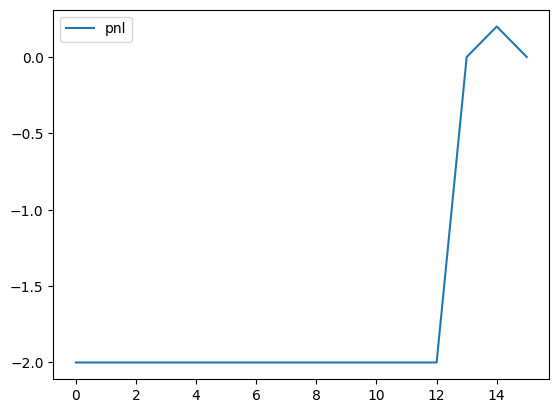

In [103]:
df.plot()